# 1.PROBLEM

An EdTech platform runs the same courses across many batches, each taught by
different instructors, and one instructor may teach several batches or courses
over time. The company wants to understand instructor effectiveness using
learner outcomes (completion, dropout, score improvement), engagement
(watch time, assignment submissions, forum activity) and feedback (ratings,
response rate).

No effectiveness label exists in the data, so the task has four parts:

1. Define an Instructor Effectiveness Score and convert it into
   Low / Medium / High tiers
2. Aggregate batch-level data into instructor-level features
3. Train a classical ML model to predict the effectiveness tier
4. Evaluate and interpret the results, including limitations

# 2.EDA


In [1]:
import pandas as pd
import numpy as np

data=pd.read_csv(r"C:\Coding Section\IIITV\InternshipAssignments\Accredian Data Science & AI Content Specialist internship\instructor_effectiveness_dataset_2000_rows.csv")

## 2.1 Basic Information about the dataset

In [2]:
print("shape of the dataset :",data.shape)
print(data.info())
print(data.describe())

shape of the dataset : (2000, 12)
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   str    
 1   instructor_id               2000 non-null   str    
 2   course_id                   2000 non-null   str    
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), str(3)
memory usage: 187.6 KB
None
       completion

## 2.2 Data Quality 

In [3]:
#checking the missing values if exist in dataset 
print(data.isnull().sum())

print()

#checking the dublicate rows if exits
print("Duplicate rows:", data.duplicated().sum())
print("Duplicate batch_id:", data["batch_id"].duplicated().sum())

print()


#how many unique batches or courses or instructor
print("Batches: ",data['batch_id'].nunique())
print("Instructors: ",data['instructor_id'].nunique())
print("courses: ", data['course_id'].nunique())

print()

##checking how many batches per instructore is assigned
batch_count=data.groupby('instructor_id')['batch_id'].nunique()
print(batch_count.sort_values(ascending=True))


batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
avg_score_improvement         0
avg_quiz_score                0
dropout_rate                  0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
dtype: int64

Duplicate rows: 0
Duplicate batch_id: 0

Batches:  2000
Instructors:  120
courses:  25

instructor_id
I_102     7
I_031     8
I_077     8
I_041     8
I_091     8
         ..
I_092    26
I_113    26
I_099    26
I_101    27
I_062    31
Name: batch_id, Length: 120, dtype: int64


#### so in 2.2 we get to know that there are no missing values and no dublicates rows our dataset is healthy

#### there are total 2000 different batches and 120 distinct intructors and 25 different courses

#### minimum course assigned to a instructor is 7 and max is 31

## 2.3 Distribution of the data

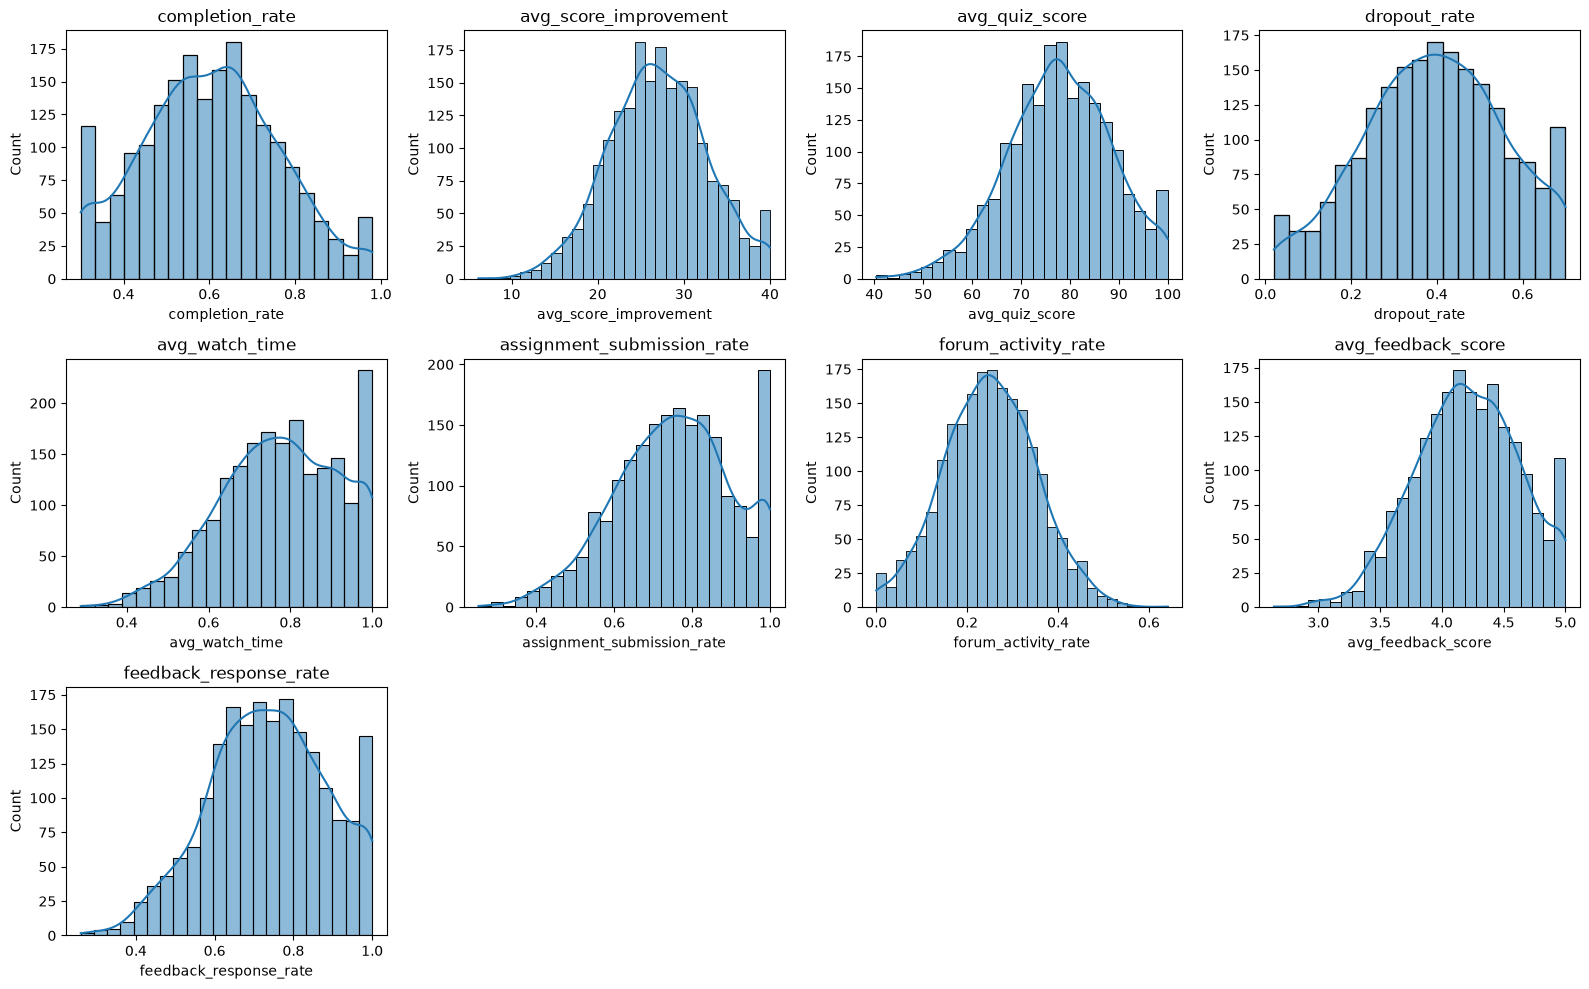

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt


id_cols = ["batch_id", "instructor_id", "course_id"]
metric_cols = [c for c in data.columns if c not in id_cols]

# One histogram per metric
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), metric_cols):
    sns.histplot(data[col], kde=True, ax=ax)
    ax.set_title(col)

for ax in axes.flatten()[len(metric_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

#### from the above figure we can conclude that completion_rate, avg_score_improvement, avg-quiz-score,drop_rate,forum_activity-rate some what like normal distribution 

#### while avg_watch_time, assignment_submission_rate,avg_feedback_score and feedback-response-rate are left skrewed

## 2.4 Outlier detection using box-plot

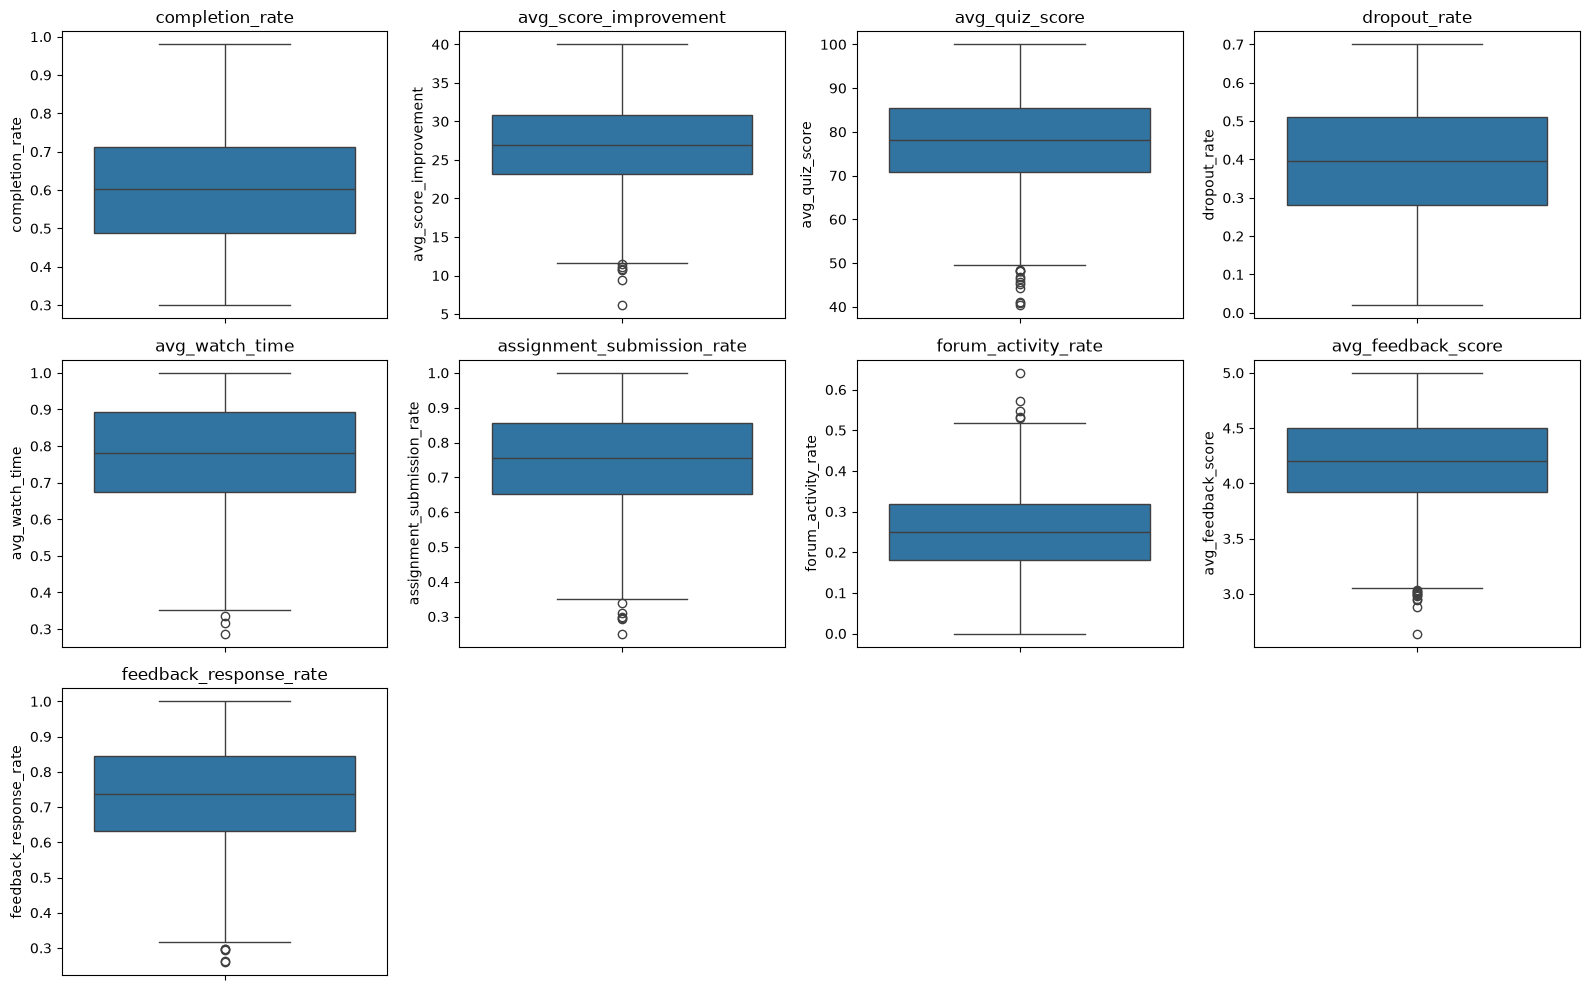

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), metric_cols):
    sns.boxplot(y=data[col], ax=ax)
    ax.set_title(col)
for ax in axes.flatten()[len(metric_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

#### as from the hist distribution the normal distributed doesnt have outlier while the other feature's data have outlier that were left skrewed

## 2.5 Correlation and relationship among the features, if the feature is totally depended then we can reduced the features to reduce dimensionality and avoid multicollinearity

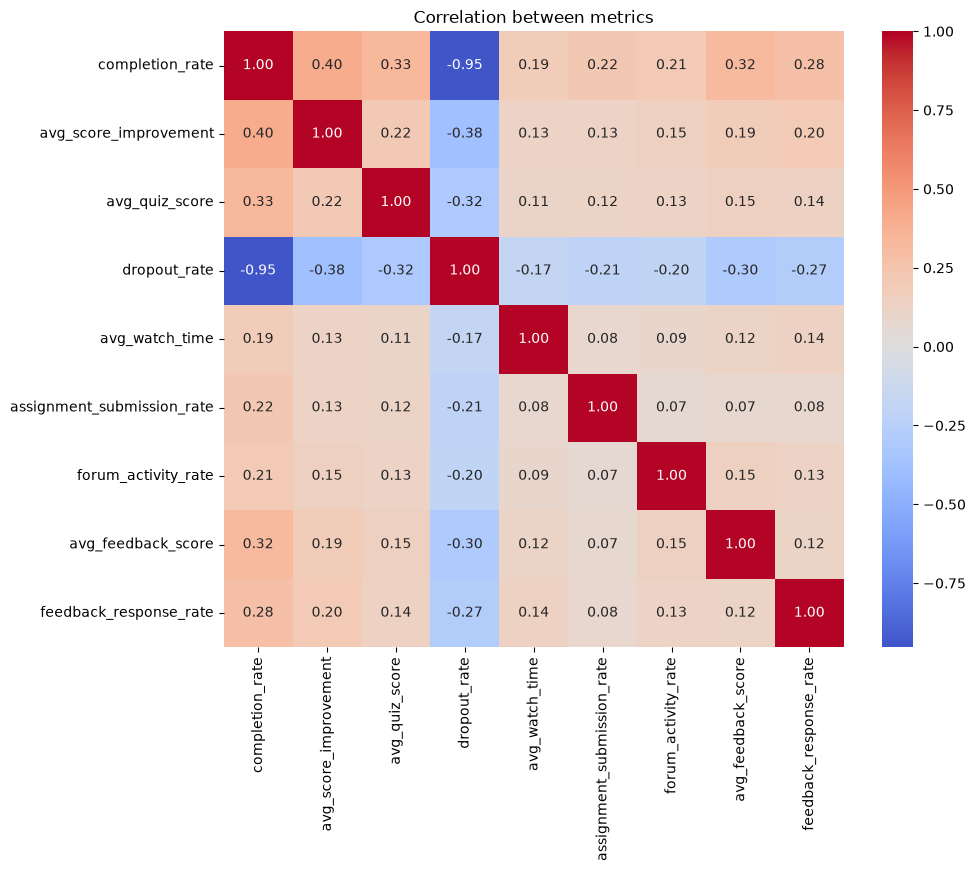

In [6]:
# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(data[metric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between metrics")
plt.show()

#### so here the completion_rate and dropout_rate have strong negative linear relationship
#### so we will check certain thing before reduction the dimensionality 

In [7]:
# are they exact mirrors?
total = data["completion_rate"] + data["dropout_rate"]
print(total.describe())
print("Rows where sum is not within 0.01 of 1:", ((total - 1).abs() > 0.01).sum())

others = [c for c in metric_cols if c not in ["completion_rate", "dropout_rate"]]

comparison = pd.DataFrame({
    "corr_with_completion": data[others].corrwith(data["completion_rate"]),
    "corr_with_dropout": data[others].corrwith(data["dropout_rate"]),
})
comparison["abs_diff"] = (comparison["corr_with_completion"].abs()
                          - comparison["corr_with_dropout"].abs())
comparison.round(3)

# Average strength of relationship with the other metrics
print(comparison[["corr_with_completion", "corr_with_dropout"]].abs().mean())


count    2000.000000
mean        0.997692
std         0.049259
min         0.828710
25%         0.965302
50%         0.999425
75%         1.029358
max         1.160438
dtype: float64
Rows where sum is not within 0.01 of 1: 1617
corr_with_completion    0.278245
corr_with_dropout       0.264746
dtype: float64


#### from the above output result we can say they are not exactly mirrors but can be redundant values, so dicision is to droped "dropout_rate" and keep "completion_rate".

### 2.5.1 Dropping the redundant feature


In [8]:
df = data.drop(columns=["dropout_rate"]).copy()

## 3.Defining Instructor Effectiveness

An effective instructor helps learners complete the course and
actually learn, and learners are satisfied with the teaching.

Let's break the feature into two major components with weight weight:

 1.Learning Outcomes(65%): completion_rate (25%), avg_score_improvement (25%), avg_quiz_score (15%)

 2.Learner feedback(35%): avg_feedback_score, adjusted for response rate

## 3.1 Batch-level score

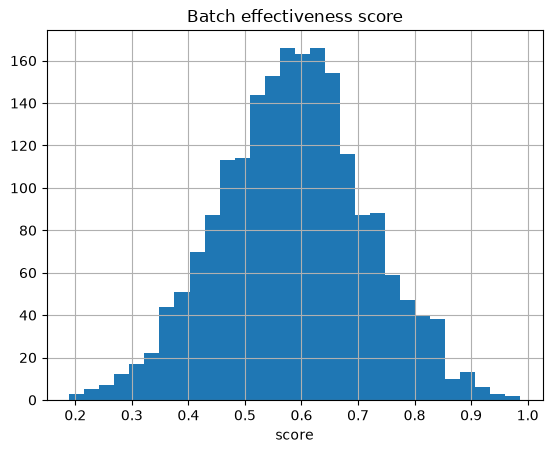

In [9]:
# Scale every metric to 0-1
def minmax(s):
    return (s - s.min()) / (s.max() - s.min())

score_df = df.copy()

# Feedback adjustment: low response rate -> pull rating toward the overall average
k = 0.3
reliability = score_df["feedback_response_rate"] / (score_df["feedback_response_rate"] + k)
overall_fb = score_df["avg_feedback_score"].mean()
score_df["adj_feedback"] = (reliability * score_df["avg_feedback_score"]
                            + (1 - reliability) * overall_fb)

# Weighted batch score (0-1)
def compute_batch_score(d, w_comp=0.25, w_imp=0.25, w_quiz=0.15, w_fb=0.35):
    return (w_comp * minmax(d["completion_rate"])
          + w_imp  * minmax(d["avg_score_improvement"])
          + w_quiz * minmax(d["avg_quiz_score"])
          + w_fb   * minmax(d["adj_feedback"]))

score_df["batch_score"] = compute_batch_score(score_df)

score_df["batch_score"].hist(bins=30)
plt.title("Batch effectiveness score")
plt.xlabel("score")
plt.show()

## 3.2 Instructor score and tiers

In [10]:
# Instructor score = average of their batch scores
instr = score_df.groupby("instructor_id")["batch_score"].agg(["mean", "count"])
instr.columns = ["effectiveness_score", "n_batches"]

# Tiers: bottom 30% --> Low, middle 40% -> Medium, top 30%->High
low_cut, high_cut = instr["effectiveness_score"].quantile([0.30, 0.70])
instr["tier"] = pd.cut(instr["effectiveness_score"],
                       bins=[-np.inf, low_cut, high_cut, np.inf],
                       labels=["Low", "Medium", "High"])

print(instr["tier"].value_counts())
print(instr["n_batches"].describe())

tier
Medium    48
Low       36
High      36
Name: count, dtype: int64
count    120.000000
mean      16.666667
std        4.582270
min        7.000000
25%       13.750000
50%       17.000000
75%       19.000000
max       31.000000
Name: n_batches, dtype: float64


## 3.3 Sanity check
Does each tier look different on the raw metrics?

In [12]:

check = score_df.merge(instr[["tier"]], left_on="instructor_id", right_index=True)
check.groupby("tier", observed=True)[["completion_rate", "avg_score_improvement",
                       "avg_quiz_score", "avg_feedback_score"]].mean().round(3)

,completion_rate,avg_score_improvement,avg_quiz_score,avg_feedback_score
tier,,,,
Low,0.452,23.463,72.816,4.018
Medium,0.605,27.257,77.908,4.203
High,0.747,30.215,83.007,4.395


All four component metrics increase consistently from low to medium to high, so the
tiers separate instructors in the intended direction. Completion rate shows the
largest relative gap (0.45 vs 0.75 between Low and High), while average feedback
differs only slightly (4.02 vs 4.40), suggesting learners rate most instructors fairly
high and that ratings alone would be a weak differentiator.

## 3.4 Sensitivity check
How much do tiers change if the weights change? (50% outcomes / 50% feedback)

In [13]:

alt = score_df.copy()
alt["batch_score"] = compute_batch_score(alt, 0.20, 0.20, 0.10, 0.50)
alt_instr = alt.groupby("instructor_id")["batch_score"].mean()
lo, hi = alt_instr.quantile([0.30, 0.70])
alt_tier = pd.cut(alt_instr, [-np.inf, lo, hi, np.inf], labels=["Low", "Medium", "High"])

changed = (alt_tier != instr["tier"]).sum()
print(f"Instructors changing tier: {changed} of {len(instr)} ({changed/len(instr):.1%})")

Instructors changing tier: 4 of 120 (3.3%)


When the weights were changed from 65% outcomes / 35% feedback to 50% -50%, only
4 of 120 instructors (3.3%) changed tier. The tiers are therefore stable with respect to the weighting assumption. 
This suggests the score reflects consistent differences between instructors
rather than an of my chosen weights.

## 3.5 Summarized

### Step 2 Summary

**Definition:** An effective instructor helps learners complete the course, actually learn, and leaves them satisfied.

**Score:** Batch score = weighted sum of min-max scaled metrics: completion (25%), score improvement (25%), quiz score (15%), and response-rate-adjusted feedback (35%). Outcomes get 65% because they measure what teaching is for. Engagement metrics are excluded to avoid circularity in the model later.

**Tiers:** Instructor score = average of their batch scores (120 instructors). Bottom 30% = Low, middle 40% = Medium, top 30% = High. Counts: Low = [ ], Medium = [ ], High = [ ].

**Checks:**
- All four component metrics rise steadily from Low to High (completion shows the biggest gap, 0.45 vs 0.75).
- Changing the weights to 50/50 moved only 4 of 120 instructors (3.3%), so the tiers are stable.